# 1. Bibliotheken importieren und Daten laden

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn import set_config
set_config(transform_output='pandas')
import plotly.graph_objects as go

In [2]:
songs_df = pd.DataFrame()
url = 'https://drive.google.com/file/d/1l9eV0mK87ACovb9ySvvyAwHnFwtmUlZx/view?usp=sharing'
path = 'https://drive.google.com/uc?export=download&id='+url.split('/')[-2]
songs_df = pd.read_csv(path)
songs_df

,Unnamed: 0,name,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,type,duration_ms,time_signature,id,html
0,0,Se Eu Quiser Falar Com Deus ...,Gilberto Gil,0.6580,0.25900,11,-13.141,0,0.0705,0.694,0.000059,0.9750,0.3060,110.376,,256213,4,1n7JnwviZ7zf0LR1tcGFq7,https://open.spotify.com/track/1n7JnwviZ7zf0LR...
1,1,Saudade De Bahia ...,Antônio Carlos Jobim,0.7420,0.39900,2,-12.646,1,0.0346,0.217,0.000002,0.1070,0.6930,125.039,,191867,4,5QGM1U0eCYrQuwSJwTm5Zq,https://open.spotify.com/track/5QGM1U0eCYrQuwS...
2,2,"Canta Canta, Minha Gente ...",Martinho Da Vila,0.8510,0.73000,2,-11.048,1,0.3470,0.453,0.000063,0.1240,0.9050,93.698,,152267,4,0NLIFSZxPzQhCwnkn5PJYs,https://open.spotify.com/track/0NLIFSZxPzQhCwn...
3,3,Mulher Eu Sei ...,Chico César,0.7050,0.05020,4,-18.115,1,0.0471,0.879,0.000041,0.3860,0.5240,106.802,,186227,4,3mXqOdlLE1k67WsAxryPFs,https://open.spotify.com/track/3mXqOdlLE1k67Ws...
4,4,Rosa Morena ...,Kurt Elling,0.6510,0.11900,6,-19.807,1,0.0380,0.916,0.000343,0.1040,0.4020,120.941,,273680,4,7bSzjzjTkWT2CkIPPdp0eA,https://open.spotify.com/track/7bSzjzjTkWT2CkI...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5230,5230,"1812 Festival Overture, Op. 49: 1812 Overture,...",Pyotr Ilyich Tchaikovsky,0.2020,0.06940,3,-23.390,1,0.0473,0.917,0.715000,0.0832,0.0655,87.906,,995000,4,1aEhYlZtypmipA06SDJ4U3,https://open.spotify.com/track/1aEhYlZtypmipA0...
5231,5231,"Winter Fragments pour ensemble instrumental, s...",Tristan Murail,0.1880,0.10100,6,-21.873,1,0.0442,0.855,0.426000,0.0694,0.0355,83.134,,855000,4,1Gfqe7TAKklmuZf6hxsH6h,https://open.spotify.com/track/1Gfqe7TAKklmuZf...
5232,5232,"Schoenberg: 5 Orchestral Pieces, Op. 16: No. 3...",Arnold Schoenberg,0.0596,0.00093,9,-42.959,1,0.0434,0.951,0.969000,0.0772,0.0344,71.573,,238187,3,2XNwnFrdMDpismp0VUZ7cU,https://open.spotify.com/track/2XNwnFrdMDpismp...
5233,5233,"Serenade For Strings In E, Op.22, B. 52: 1. Mo...",Antonín Dvořák,0.1330,0.02080,4,-29.443,1,0.0419,0.883,0.505000,0.1110,0.0591,67.109,,314307,4,7ucDwgMtE3YJtEfTbuRhy0,https://open.spotify.com/track/7ucDwgMtE3YJtEf...


In [ ]:
songs_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5235 entries, 0 to 5234
Data columns (total 19 columns):
 #   Column                                                                                                                                                                             Non-Null Count  Dtype  
---  ------                                                                                                                                                                             --------------  -----  
 0   Unnamed: 0                                                                                                                                                                         5235 non-null   int64  
 1   name                                                                                                                                                                               5235 non-null   object 
 2   artist                                                  

# Leerzeichen am Anfang und Ende der Spaltennamen entfernen

In [3]:
songs_df.columns = songs_df.columns.str.strip()

In [ ]:
songs_df.columns.to_list()

['Unnamed: 0',
 'name',
 'artist',
 'danceability',
 'energy',
 'key',
 'loudness',
 'mode',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'type',
 'duration_ms',
 'time_signature',
 'id',
 'html']

# Die Spalten `Unnamed`, `id`,  `name`, `type`, `artist` und `html` entfernen, da sie keine numerischen Merkmale für das Clustering enthalten

In [4]:
columus_drop = ['Unnamed: 0','name','artist','type','id', 'html']
songs_copy_df = songs_df.drop(columns= columus_drop).copy()
songs_copy_df

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
0,0.6580,0.25900,11,-13.141,0,0.0705,0.694,0.000059,0.9750,0.3060,110.376,256213,4
1,0.7420,0.39900,2,-12.646,1,0.0346,0.217,0.000002,0.1070,0.6930,125.039,191867,4
2,0.8510,0.73000,2,-11.048,1,0.3470,0.453,0.000063,0.1240,0.9050,93.698,152267,4
3,0.7050,0.05020,4,-18.115,1,0.0471,0.879,0.000041,0.3860,0.5240,106.802,186227,4
4,0.6510,0.11900,6,-19.807,1,0.0380,0.916,0.000343,0.1040,0.4020,120.941,273680,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5230,0.2020,0.06940,3,-23.390,1,0.0473,0.917,0.715000,0.0832,0.0655,87.906,995000,4
5231,0.1880,0.10100,6,-21.873,1,0.0442,0.855,0.426000,0.0694,0.0355,83.134,855000,4
5232,0.0596,0.00093,9,-42.959,1,0.0434,0.951,0.969000,0.0772,0.0344,71.573,238187,3
5233,0.1330,0.02080,4,-29.443,1,0.0419,0.883,0.505000,0.1110,0.0591,67.109,314307,4


In [ ]:
songs_copy_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5235 entries, 0 to 5234
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   danceability      5235 non-null   float64
 1   energy            5235 non-null   float64
 2   key               5235 non-null   int64  
 3   loudness          5235 non-null   float64
 4   mode              5235 non-null   int64  
 5   speechiness       5235 non-null   float64
 6   acousticness      5235 non-null   float64
 7   instrumentalness  5235 non-null   float64
 8   liveness          5235 non-null   float64
 9   valence           5235 non-null   float64
 10  tempo             5235 non-null   float64
 11  duration_ms       5235 non-null   int64  
 12  time_signature    5235 non-null   int64  
dtypes: float64(9), int64(4)
memory usage: 531.8 KB


# Daten skalieren

In [5]:
my_min_max_scaler = MinMaxScaler()
scaled_songs_df = my_min_max_scaler.fit_transform(songs_copy_df)
scaled_songs_df

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
0,0.680455,0.25900,1.000000,0.763897,0.0,0.076797,0.696787,0.000060,0.987842,0.310660,0.515800,0.059067,0.8
1,0.767322,0.39900,0.181818,0.771967,1.0,0.037691,0.217871,0.000002,0.108409,0.703553,0.584322,0.042058,0.8
2,0.880041,0.73000,0.181818,0.798018,1.0,0.377996,0.454819,0.000064,0.125633,0.918782,0.437862,0.031590,0.8
3,0.729059,0.05020,0.363636,0.682811,1.0,0.051307,0.882530,0.000041,0.391084,0.531980,0.499098,0.040567,0.8
4,0.673216,0.11900,0.545455,0.655228,1.0,0.041394,0.919679,0.000348,0.105370,0.408122,0.565171,0.063684,0.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5230,0.208893,0.06940,0.272727,0.596818,1.0,0.051525,0.920683,0.725888,0.084296,0.066497,0.410795,0.254357,0.8
5231,0.194416,0.10100,0.545455,0.621548,1.0,0.048148,0.858434,0.432487,0.070314,0.036041,0.388495,0.217350,0.8
5232,0.061634,0.00093,0.818182,0.277803,1.0,0.047277,0.954819,0.983756,0.078217,0.034924,0.334469,0.054302,0.6
5233,0.137539,0.02080,0.363636,0.498142,1.0,0.045643,0.886546,0.512690,0.112462,0.060000,0.313608,0.074424,0.8


In [ ]:
scaled_songs_df.shape

(5235, 13)

# PCA – Principal Component Analysis

PCA ist ein Verfahren zur Dimensionsreduktion. Zunächst berechnen wir alle Hauptkomponenten der Songdaten. Anschließend untersuchen wir, wie viel Varianz jede Hauptkomponente erklärt, um die geeignete Anzahl der Komponenten zu bestimmen.

In [6]:
# PCA-Modell mit zwei Hauptkomponenten erstellen
my_pca = PCA()

# PCA-Modell an die skalierten Songdaten anpassen
my_pca.fit(scaled_songs_df)

# Skalierte Songdaten in den neuen Merkmalsraum transformieren
pca_songs_df = my_pca.transform(scaled_songs_df)

pca_songs_df

,pca0,pca1,pca2,pca3,pca4,pca5,pca6,pca7,pca8,pca9,pca10,pca11,pca12
0,-0.094419,-0.757884,0.504083,0.438636,-0.257086,0.554242,0.560851,0.197453,-0.102738,0.022729,-0.013079,0.005804,-0.006255
1,-0.017481,0.453019,0.384560,-0.225555,0.082847,-0.174383,0.038690,0.109702,-0.174917,0.011962,-0.017243,-0.015519,-0.011982
2,-0.126719,0.504107,0.471724,-0.230476,0.276667,-0.007994,0.037417,-0.139534,0.165436,-0.016899,0.289205,-0.069875,-0.010251
3,0.505367,0.184282,0.811681,-0.006984,-0.074671,0.106656,0.223721,0.101924,-0.086820,0.029381,0.008400,-0.013775,-0.021077
4,0.542908,0.131782,0.744387,0.172948,-0.151485,-0.082936,0.009560,0.093759,0.027305,0.032008,-0.005094,-0.063066,0.002000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5230,1.177483,-0.113871,0.123871,-0.106151,-0.116104,-0.081500,0.002337,-0.068789,-0.079293,0.077375,0.018366,-0.012382,0.173650
5231,0.974406,-0.069205,0.211216,0.173331,-0.305723,-0.099305,-0.023697,-0.105861,-0.101755,0.077026,0.011342,-0.012386,0.137500
5232,1.400419,-0.327087,-0.021031,0.424738,0.000413,-0.089724,-0.013262,-0.144308,-0.239323,-0.108310,0.059216,-0.248719,-0.038534
5233,1.101864,-0.089709,0.222889,-0.004583,-0.271117,-0.073719,0.017510,-0.163171,-0.201389,0.084121,0.031439,-0.087537,-0.011667


# Erklärte Varianz der Hauptkomponenten analysieren
  Mit dem Attribut `explained_variance_ratio_` untersuchen wir, welchen Anteil der Gesamtvarianz jede Hauptkomponente erklärt. Die Hauptkomponenten sind nach ihrem erklärten Varianzanteil geordnet: Die erste Hauptkomponente erklärt den größten Anteil, gefolgt von der zweiten und den weiteren Komponenten. Diese Analyse hilft uns, die geeignete Anzahl der Hauptkomponenten für die Dimensionsreduktion zu bestimmen.

In [7]:

explained_variance_array = my_pca.explained_variance_

explained_variance_array

array([0.24666354, 0.23092772, 0.16183796, 0.10092843, 0.05368677,
       0.02440994, 0.02000858, 0.01569818, 0.01316999, 0.00651008,
       0.00532668, 0.00222093, 0.00117778])

 # Elbow methode

In [8]:
# Erklärte Varianzanteile in einem DataFrame speichern
explained_variance_array_df = pd.DataFrame(explained_variance_array, columns=['variance_explained'])

# DataFrame anzeigen
explained_variance_array_df

,variance_explained
0,0.246664
1,0.230928
2,0.161838
3,0.100928
4,0.053687
5,0.024410
6,0.020009
7,0.015698
8,0.013170
9,0.006510


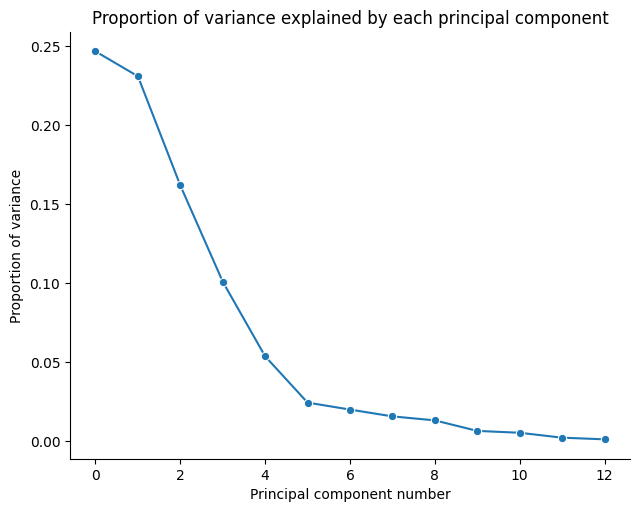

In [9]:
# Liniendiagramm mit Seaborn erstellen
sns.relplot(
    kind='line',
    data=explained_variance_array_df,
    x=explained_variance_array_df.index,
    y='variance_explained',
    marker='o',
    aspect=1.3
).set(
    # Titel des Diagramms festlegen
    title='Proportion of variance explained by each principal component'
).set_axis_labels(
    # Achsenbeschriftungen festlegen
    'Principal component number',
    'Proportion of variance'
)

# Interpretation des Elbow-Diagramms

  Das Diagramm zeigt den erklärten Varianzanteil jeder Hauptkomponente. Die ersten Hauptkomponenten erklären einen großen Teil der Gesamtvarianz. Besonders zwischen der zweiten und der fünften Hauptkomponente nimmt der erklärte Varianzanteil deutlich ab. Ab der fünften Hauptkomponente wird der Rückgang wesentlich geringer.

Der Verlauf deutet auf einen möglichen Knick im Bereich der fünften Hauptkomponente hin. Dieser Punkt kann als Orientierung für die Auswahl der Anzahl der Hauptkomponenten dienen. Die endgültige Entscheidung treffen wir jedoch erst nach der Analyse der kumulativen erklärten Varianz.

# Kumulative erklärte Varianz analysieren
  Die kumulative erklärte Varianz zeigt, wie viel der Gesamtvarianz durch mehrere Hauptkomponenten zusammen erklärt wird. Wir berechnen die kumulierten Varianzanteile, um zu bestimmen, wie viele Hauptkomponenten erforderlich sind, um einen bestimmten Anteil der Varianz, beispielsweise 90 % oder 95 %, zu erhalten.

In [10]:
elbow = 6

pca_elbow = PCA(n_components= elbow)

pca_elbow_df = pca_elbow.fit_transform(scaled_songs_df)

pca_elbow_df

,pca0,pca1,pca2,pca3,pca4,pca5
0,-0.094419,-0.757884,0.504083,0.438636,-0.257086,0.554242
1,-0.017481,0.453019,0.384560,-0.225555,0.082847,-0.174383
2,-0.126719,0.504107,0.471724,-0.230476,0.276667,-0.007994
3,0.505367,0.184282,0.811681,-0.006984,-0.074671,0.106656
4,0.542908,0.131782,0.744387,0.172948,-0.151485,-0.082936
...,...,...,...,...,...,...
5230,1.177483,-0.113871,0.123871,-0.106151,-0.116104,-0.081500
5231,0.974406,-0.069205,0.211216,0.173331,-0.305723,-0.099305
5232,1.400419,-0.327087,-0.021031,0.424738,0.000413,-0.089724
5233,1.101864,-0.089709,0.222889,-0.004583,-0.271117,-0.073719


# Anzahl der Hauptkomponenten anhand der kumulativen Varianz bestimmen

  In diesem Schritt berechnen wir die kumulative erklärte Varianz der Hauptkomponenten. Dadurch können wir bestimmen, wie viele Hauptkomponenten benötigt werden, um einen bestimmten Anteil der Gesamtvarianz, beispielsweise 95 %, zu erklären. Anschließend verwenden wir die ausgewählten Hauptkomponenten für das Clustering der Songs.

In [11]:
scaled_songs_df

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
0,0.680455,0.25900,1.000000,0.763897,0.0,0.076797,0.696787,0.000060,0.987842,0.310660,0.515800,0.059067,0.8
1,0.767322,0.39900,0.181818,0.771967,1.0,0.037691,0.217871,0.000002,0.108409,0.703553,0.584322,0.042058,0.8
2,0.880041,0.73000,0.181818,0.798018,1.0,0.377996,0.454819,0.000064,0.125633,0.918782,0.437862,0.031590,0.8
3,0.729059,0.05020,0.363636,0.682811,1.0,0.051307,0.882530,0.000041,0.391084,0.531980,0.499098,0.040567,0.8
4,0.673216,0.11900,0.545455,0.655228,1.0,0.041394,0.919679,0.000348,0.105370,0.408122,0.565171,0.063684,0.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5230,0.208893,0.06940,0.272727,0.596818,1.0,0.051525,0.920683,0.725888,0.084296,0.066497,0.410795,0.254357,0.8
5231,0.194416,0.10100,0.545455,0.621548,1.0,0.048148,0.858434,0.432487,0.070314,0.036041,0.388495,0.217350,0.8
5232,0.061634,0.00093,0.818182,0.277803,1.0,0.047277,0.954819,0.983756,0.078217,0.034924,0.334469,0.054302,0.6
5233,0.137539,0.02080,0.363636,0.498142,1.0,0.045643,0.886546,0.512690,0.112462,0.060000,0.313608,0.074424,0.8


In [12]:
my_pca = PCA(n_components=0.95)

pca_songs_df = my_pca.fit_transform(scaled_songs_df)

explained_variance_array = my_pca.explained_variance_ratio_

explained_variance_array

array([0.27948434, 0.26165474, 0.18337196, 0.11435786, 0.06083028,
       0.0276579 , 0.0226709 ])

In [13]:
pca_songs_df.shape

(5235, 7)

# K-Means-Clustering mit PCA-Daten
  In diesem Schritt wenden wir den K-Means-Algorithmus auf die PCA-transformierten Songdaten an. Dafür verwenden wir die ausgewählten Hauptkomponenten anstelle der ursprünglichen Merkmale. Ziel ist es, Songs mit ähnlichen Eigenschaften in Gruppen zusammenzufassen und anschließend die entstandenen Cluster zu analysieren.

# Optimale Anzahl der Cluster bestimmen
  Bevor wir K-Means anwenden, untersuchen wir, welche Anzahl von Clustern für die PCA-transformierten Songdaten geeignet ist. Dazu können wir die Elbow-Methode und den Silhouette Score verwenden und die Ergebnisse mit denen der ursprünglichen Songdaten vergleichen.

In [14]:
# Zufallszustand für reproduzierbare Ergebnisse festlegen
random_seed = 42

# Maximale Anzahl der Cluster bestimmen
max_k = 10

# Liste für die Inertia-Werte initialisieren
inertia_list = []

# Verschiedene Cluster-Anzahlen testen
for k in range(1, max_k+1):

  # K-Means-Modell erstellen
  songs_kmeans = KMeans(n_clusters= k, random_state= random_seed, n_init='auto')

  # Modell mit den skalierten Daten trainieren
  songs_kmeans.fit(pca_songs_df)

  # Inertia-Wert des Modells abrufen
  inertia =songs_kmeans.inertia_

  # Inertia-Wert zur Liste hinzufügen
  inertia_list.append(inertia)

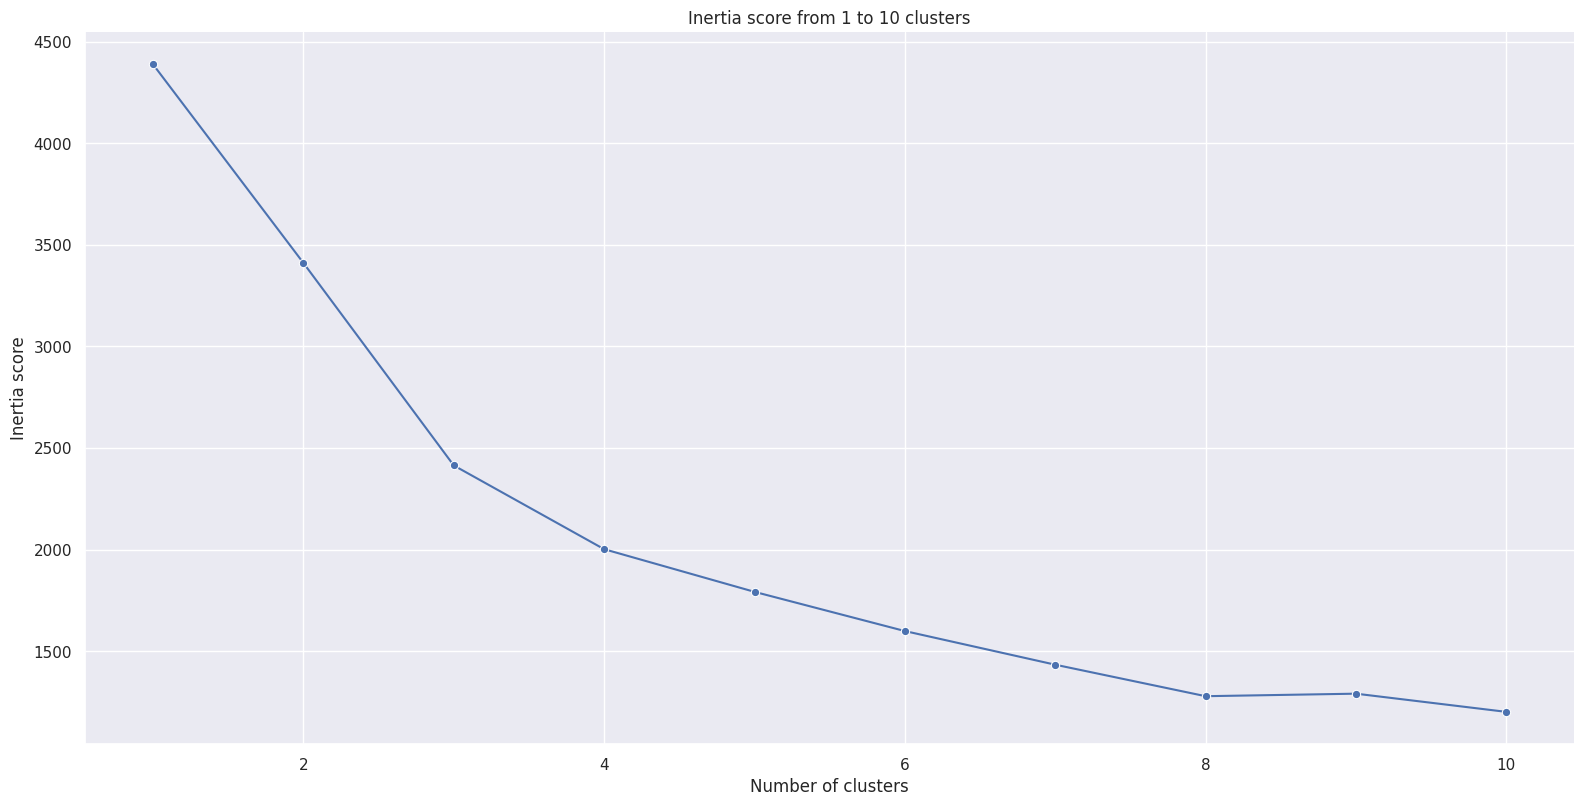

In [15]:
# Seaborn-Design festlegen
sns.set_theme(style='darkgrid')

(
# Inertia-Werte als Liniendiagramm darstellen
sns.relplot(y = inertia_list,
            x = range(1, max_k + 1),
            kind = 'line',
            marker = 'o',
            height = 8,
            aspect = 2)
# Titel des Diagramms festlegen
.set(title=f"Inertia score from 1 to {max_k} clusters")
# Achsenbeschriftungen festlegen
.set_axis_labels("Number of clusters", "Inertia score")
);

Das Diagramm zeigt die Inertia-Werte für unterschiedliche Cluster-Anzahlen. Zwischen einem und drei Clustern sinkt die Inertia stark. Danach nimmt sie weiterhin ab, jedoch zunehmend langsamer. Ein möglicher Knick liegt bei etwa vier Clustern. Daher ist \(k = 4\) ein erster Kandidat für die Anzahl der Cluster. Zur weiteren Beurteilung betrachten wir zusätzlich den Silhouette Score.

# Silhouette-Methode
  Der Silhouette Score bewertet, wie gut die Songs ihrem jeweiligen Cluster zugeordnet sind und wie deutlich sich die Cluster voneinander unterscheiden. Wir vergleichen die Werte für verschiedene Cluster-Anzahlen. Ein höherer Silhouette Score weist in der Regel auf eine bessere Trennung und Zuordnung der Cluster hin.

In [16]:
# Zufallszustand für reproduzierbare Ergebnisse festlegen
random_seed = 42

# Liste für die Silhouette Scores initialisieren
sil_scores =[]

# Maximale Anzahl der Cluster bestimmen
max_k = 10

# Verschiedene Cluster-Anzahlen testen
for k in range(2,max_k) :

  # K-Means-Modell erstellen
  songs_KMeans = KMeans(n_clusters=k, random_state=random_seed, n_init='auto')

  # Modell mit den skalierten Daten trainieren
  songs_KMeans.fit(pca_songs_df)

  # Silhouette Score berechnen
  sil_value = silhouette_score(pca_songs_df, songs_KMeans.labels_)

  # Silhouette Score zur Liste hinzufügen
  sil_scores.append(sil_value)

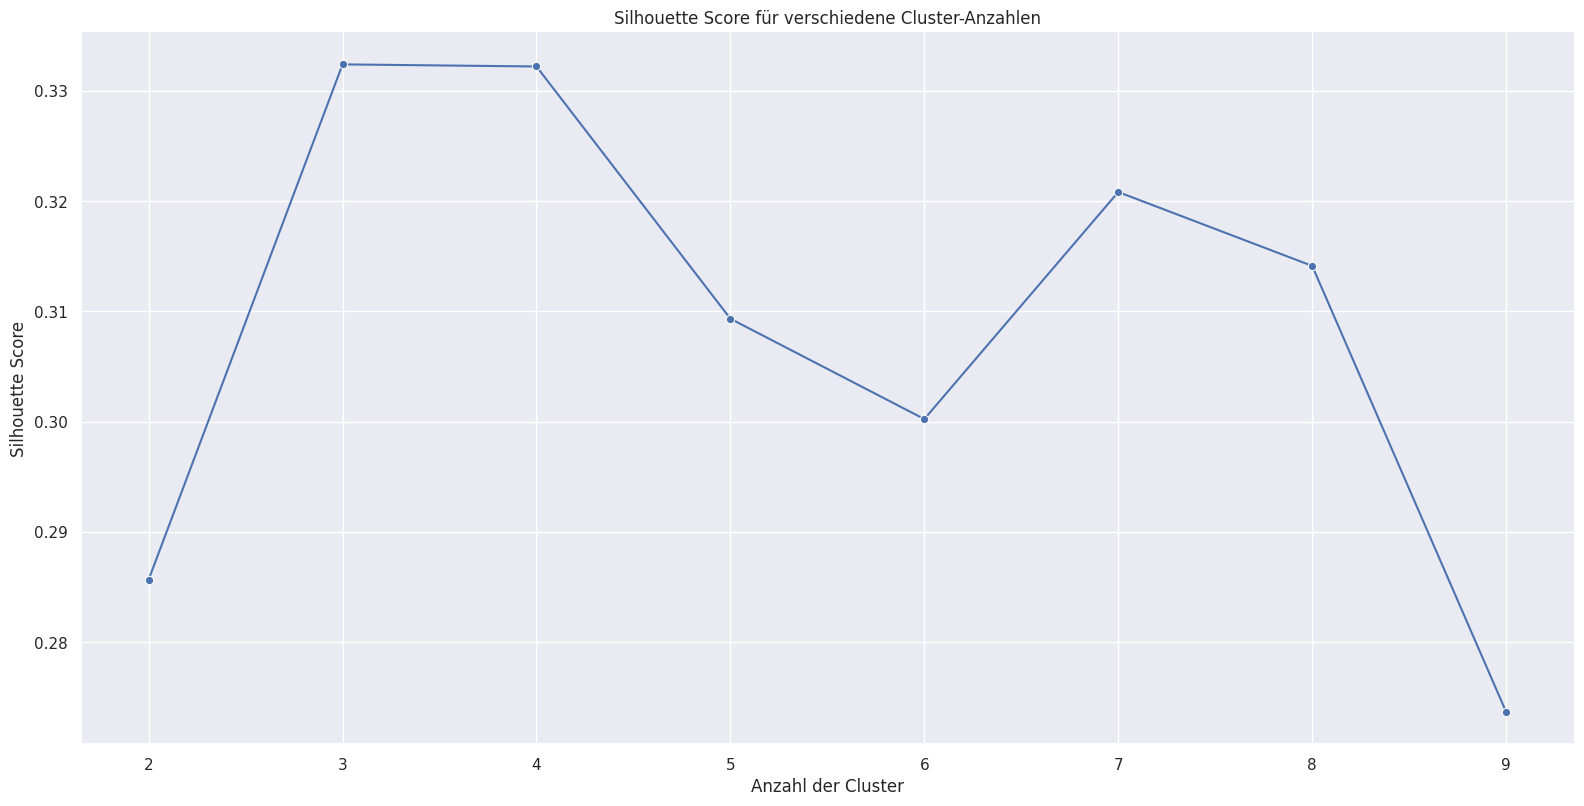

In [17]:
# Silhouette Scores als Liniendiagramm darstellen
sns.relplot(
    kind='line',
    data=pd.DataFrame({
        'Anzahl der Cluster': range(2, len(sil_scores) + 2),
        'Silhouette Score': sil_scores
    }),
    x='Anzahl der Cluster',
    y='Silhouette Score',
    marker='o',
    height=8,
    aspect=2
).set(
    title='Silhouette Score für verschiedene Cluster-Anzahlen'
);

Der Silhouette Score erreicht bei drei und vier Clustern mit etwa 0,332 seine höchsten Werte. Dies deutet darauf hin, dass die Songs bei diesen Cluster-Anzahlen vergleichsweise gut den jeweiligen Clustern zugeordnet und voneinander getrennt werden. Zusammen mit der Elbow-Methode spricht das Ergebnis dafür, vier Cluster als nächsten Kandidaten zu untersuchen.

# K-Means mit vier Clustern anwenden
  Auf Grundlage der Ergebnisse beider Bewertungsmethoden verwenden wir zunächst vier Cluster. Wir trainieren das K-Means-Modell auf den PCA-transformierten Songdaten und ordnen jedem Song ein Cluster zu. Anschließend untersuchen wir die Verteilung der Songs auf die Cluster.

In [18]:
# K-Means-Modell initialisieren
songs_KMeans = KMeans(n_clusters=4, random_state=42, n_init='auto')

# Modell mit den skalierten Daten trainieren
songs_KMeans.fit(pca_songs_df)

# Cluster-Zuordnungen zum DataFrame hinzufügen
pca_songs_df['cluster'] = songs_KMeans.labels_
pca_songs_df

,pca0,pca1,pca2,pca3,pca4,pca5,pca6,cluster
0,-0.094419,-0.757884,0.504083,0.438636,-0.257086,0.554242,0.560851,2
1,-0.017481,0.453019,0.384560,-0.225555,0.082847,-0.174383,0.038690,1
2,-0.126719,0.504107,0.471724,-0.230476,0.276667,-0.007994,0.037417,1
3,0.505367,0.184282,0.811681,-0.006984,-0.074671,0.106656,0.223721,0
4,0.542908,0.131782,0.744387,0.172948,-0.151485,-0.082936,0.009560,0
...,...,...,...,...,...,...,...,...
5230,1.177483,-0.113871,0.123871,-0.106151,-0.116104,-0.081500,0.002337,0
5231,0.974406,-0.069205,0.211216,0.173331,-0.305723,-0.099305,-0.023697,0
5232,1.400419,-0.327087,-0.021031,0.424738,0.000413,-0.089724,-0.013262,0
5233,1.101864,-0.089709,0.222889,-0.004583,-0.271117,-0.073719,0.017510,0


# Verteilung der Songs auf die Cluster untersuchen
  In diesem Schritt untersuchen wir, wie viele Songs den einzelnen Clustern zugeordnet wurden. Dadurch erkennen wir, ob die Songs gleichmäßig verteilt sind oder ob bestimmte Cluster deutlich mehr Songs enthalten als andere.

In [19]:
# Anzahl der Songs pro Cluster berechnen
cluster_counts = pca_songs_df['cluster'].value_counts().sort_index()

# Verteilung der Songs auf die Cluster anzeigen
cluster_counts

,count
cluster,
0,826
1,2179
2,1378
3,852


Die Verteilung zeigt, dass die vier Cluster unterschiedlich groß sind. Cluster 1 enthält mit 2.179 Songs die meisten Einträge, gefolgt von Cluster 2 mit 1.378 Songs. Cluster 0 und Cluster 3 enthalten jeweils weniger als 900 Songs. Unterschiedliche Cluster-Größen sind bei K-Means möglich und stellen nicht automatisch ein Problem dar. Um die Bedeutung der Cluster besser zu verstehen, müssen wir nun die musikalischen Merkmale untersuchen.

#  Musikalische Merkmale der Cluster analysieren

  In diesem Schritt analysieren wir die durchschnittlichen Werte der ursprünglichen musikalischen Merkmale innerhalb der vier Cluster. Dazu verbinden wir die Cluster-Zuordnungen mit den ursprünglichen Songdaten. So können wir die musikalischen Eigenschaften der einzelnen Cluster vergleichen und besser verstehen, wodurch sich die Songgruppen unterscheiden.

In [20]:
# Ursprüngliche Songdaten für die Clusteranalyse vorbereiten
songs_cluster_df = songs_copy_df.copy()

# Cluster-Zuordnungen zu den ursprünglichen Songdaten hinzufügen
songs_cluster_df['cluster'] = songs_KMeans.labels_

# Daten überprüfen
songs_cluster_df.head()

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,cluster
0,0.658,0.2590,11,-13.141,0,0.0705,0.694,0.000059,0.975,0.306,110.376,256213,4,2
1,0.742,0.3990,2,-12.646,1,0.0346,0.217,0.000002,0.107,0.693,125.039,191867,4,1
2,0.851,0.7300,2,-11.048,1,0.3470,0.453,0.000063,0.124,0.905,93.698,152267,4,1
3,0.705,0.0502,4,-18.115,1,0.0471,0.879,0.000041,0.386,0.524,106.802,186227,4,0
4,0.651,0.1190,6,-19.807,1,0.0380,0.916,0.000343,0.104,0.402,120.941,273680,4,0


In [21]:
# Durchschnittliche musikalische Merkmale pro Cluster berechnen
cluster_means = songs_cluster_df.groupby('cluster').mean(numeric_only=True)

# Durchschnittswerte der Cluster anzeigen
cluster_means

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
cluster,,,,,,,,,,,,,
0,0.344852,0.144891,5.119855,-20.465178,0.675545,0.045687,0.926562,0.644621,0.146006,0.192121,105.632610,315900.539952,3.694915
1,0.595212,0.706830,4.870583,-7.179645,1.000000,0.083299,0.220887,0.026049,0.187284,0.567160,121.111956,226407.994034,3.962368
2,0.615463,0.720177,6.073295,-6.819279,0.000000,0.093152,0.191231,0.074763,0.195491,0.526702,120.872438,236193.190131,3.953556
3,0.278553,0.902751,5.042254,-8.144712,0.758216,0.103085,0.009633,0.768682,0.202166,0.236971,121.817908,255943.532864,3.870892


Die durchschnittlichen Merkmalswerte zeigen deutliche Unterschiede zwischen den vier Clustern. Cluster 0 zeichnet sich durch eine hohe Acousticness und eine niedrige Energy aus. Cluster 1 und Cluster 2 weisen eine höhere Danceability und Energy auf und ähneln sich in mehreren Merkmalen. Cluster 3 besitzt die höchste Energy, eine sehr niedrige Acousticness und eine hohe Instrumentalness. Diese Unterschiede helfen uns, die musikalischen Eigenschaften der Songgruppen besser zu interpretieren. Die Cluster-Bezeichnungen sind zunächst vorläufig und stellen keine bestätigten Musikgenres dar.

# Radar Chart

Nachdem wir die durchschnittlichen Werte der musikalischen Merkmale für jedes Cluster berechnet haben, können wir diese mit einem Radar Chart visualisieren. Dadurch lassen sich die verschiedenen Songgruppen leichter vergleichen und ihre musikalischen Eigenschaften besser verstehen.

Die Visualisierung hilft uns, Muster und Unterschiede zwischen den Clustern zu erkennen. Beispielsweise können wir untersuchen, welche Cluster eine hohe Energie, eine hohe Tanzbarkeit oder eine ausgeprägte Instrumentalität aufweisen. Andere Cluster können sich durch eine höhere Akustik, eine geringere Energie oder andere Merkmalskombinationen auszeichnen.

So können wir die Cluster anhand ihrer musikalischen Merkmale interpretieren und besser nachvollziehen, welche Arten von Songs die einzelnen Gruppen charakterisieren.

In [22]:
# Create an empty list to store the Scatterpolar object of each cluster
scatter_objects = []

# State the label for each arm of the chart
categories = songs_cluster_df.columns

# Get the means of each feature for each cluster
cluster_feat_means = cluster_means

# Iterate over the unique clusters and add an object for each cluster to the list
for cluster in sorted(songs_cluster_df['cluster'].unique()):

  # Find the mean value for each column of the cluster
  cluster_means = cluster_feat_means.loc[cluster]

  # Create a Scatterpolar object for the cluster
  cluster_scatter = go.Scatterpolar(
    r = cluster_means, # set the radial coordinates
    theta = categories, # the names of the columns
    fill = 'toself', # fills in the space with colour
    name = f'Cluster {cluster}' # adds the name of the cluster
  )

  # Add the Scatterpolar object to the list
  scatter_objects.append(cluster_scatter)

# Create the figure (the white area)
fig = go.Figure()

# Add the scatter objects to the figure
fig.add_traces(scatter_objects)

# Add extras to the plot, such as title
fig.update_layout(
  title_text = 'Radar chart of mean songs preferences by cluster',
  height = 600,
  width = 800,
  polar = dict(
    radialaxis = dict(
      visible = True, # visibility of the numbers on the arm
      range = [0, 1] # scale of the plot
    )),
  showlegend = True
)

# Show the initialised plot and the trace objects
fig.show()